<a href="https://colab.research.google.com/github/frandresst-wq/Proyecto-de-Ciencia-de-Datos/blob/main/S3_Entrega2_SOTO_FRANCO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 3 — Análisis exploratorio de tu conjunto de datos
**Ciencia de Datos · Semana 3 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 1) · RA3 (transversal) |
| **Duración estimada** | 1,5 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `mi_conjunto_limpio.csv`, producido en la semana 2 |
| **Producto** | Este cuaderno completo — **es la Entrega 2** |
| **Estudiante** | _(Franco Soto Soto)_ |

---



**Este cuaderno es la entrega.** No hay informe aparte. Lo que se evalúa es que cada resultado venga acompañado de su lectura: *un resultado sin interpretación no es un hallazgo, es un número suelto*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20263
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

df = pd.read_csv(RUTA + 'mi_conjunto_limpio.csv', sep=';')
print('Forma:', df.shape)
df.head()

Forma: (20262, 20)


,ano,mes,division,grupo,clase,subclase,producto,glosa,ponderacion,indice,variacion_mensual_pct,variacion_acumulada_pct,variacion_12_meses_pct,incidencia_mensual_pct,incidencia_acumulada_pct,incidencia_12_meses_pct,fecha,codigo_jerarquico,nivel_jerarquico,aporte_relativo_acum_pct
0,2024,1,0,0,0,0,0,IPC GENERAL,NaN,101.72,0.7,0.7,3.8,NaN,NaN,NaN,2024-01-01,0.0.0.0.0,0_IPC_General,NaN
1,2024,1,1,0,0,0,0,ALIMENTOS Y BEBIDAS NO ALCOHOLICAS,22.15348,103.26,1.0,1.0,NaN,0.215,0.215,NaN,2024-01-01,1.0.0.0.0,1_Division,32.14
2,2024,1,1,1,0,0,0,ALIMENTOS,19.91270,103.14,0.8,0.8,NaN,0.158,0.158,NaN,2024-01-01,1.1.0.0.0,2_Grupo,23.62
3,2024,1,1,1,1,0,0,"PAN, CEREALES, HARINAS Y PASTAS",4.29417,102.10,1.0,1.0,NaN,0.045,0.045,NaN,2024-01-01,1.1.1.0.0,3_Clase,6.73
4,2024,1,1,1,1,1,0,ARROZ,0.22304,106.30,-0.1,-0.1,NaN,0.000,0.000,NaN,2024-01-01,1.1.1.1.0,4_Subclase,0.00


### Punto de partida

Antes de explorar, recuerda a dónde vas. Copia aquí lo que escribiste en la Entrega 1:

- **Mi pregunta analítica es:**_¿Qué divisiones del IPC explican la variación acumulada del último año?_
- **Una fila de mi conjunto representa:** _Cada fila del conjunto de datos (20.262 registros en total) representa una observación mensual de precios e incidencias para un ítem o nivel de agregación específico de la canasta del IPC en un período determinado._

Todo lo que sigue debe servir para responder esa pregunta. Si un gráfico no aporta a ella, sobra.

---
## Parte 1 · Análisis univariado

Una variable a la vez. El objetivo es conocer la forma de cada una antes de relacionarlas.\
+++++ El análisis univariado consiste en estudiar una variable a la vez, sin relacionarla todavía con otras variables del conjunto de datos.

Su objetivo es conocer cómo se distribuyen los valores, identificar valores extremos, detectar posibles anomalías y comprender el comportamiento general de cada variable.

In [2]:
# Resumen numérico de todas las variables cuantitativas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ano,20262.0,2024.91,0.79,2024.00,2024.00,2025.00,2026.00,2026.00
mes,20262.0,6.09,3.31,1.00,3.00,6.00,9.00,12.00
division,20262.0,5.56,3.68,0.00,2.00,5.00,9.00,13.00
grupo,20262.0,2.15,1.59,0.00,1.00,2.00,3.00,8.00
clase,20262.0,2.22,2.15,0.00,1.00,1.00,3.00,9.00
subclase,20262.0,1.34,1.33,0.00,0.00,1.00,2.00,7.00
producto,20262.0,0.89,1.46,0.00,0.00,0.00,1.00,10.00
ponderacion,20229.0,0.82,1.86,0.01,0.10,0.25,0.75,22.15
indice,20262.0,105.31,12.11,57.02,99.66,104.84,110.51,217.15
variacion_mensual_pct,20262.0,0.28,3.11,-27.90,-0.60,0.10,1.10,45.70


1. Análisis de cada variable\
- ano: Año calendario de la medición (rango de 2024 a 2026). Su media (2024,91) no tiene significado como magnitud continua, solo refleja que 2024 y 2025 tienen 12 meses completos y 2026 tiene 9 meses (enero a septiembre).\
- mes: Mes calendario del registro (1 para enero a 12 para diciembre). Su promedio (6,09) es únicamente referencial.\
- division: Código identificador de las 13 divisiones de consumo COICOP (1 a 13), más el valor 0 que identifica al IPC GENERAL. Su promedio (5,56) carece de interpretación estadística.\
- grupo, clase, subclase, producto: Códigos numéricos anidados que identifican la posición del ítem en el árbol jerárquico de la canasta (0 indica que la fila pertenece a un nivel superior de agregación; valores 1 a 10 indican la desagregación específica). Tampoco deben interpretarse sus promedios.

2. Hallazgos importantes\
A. Efecto de mezclar niveles jerárquicos: Variables aditivas como ponderacion e incidencia_acumulada_pct tienen el 75% de sus datos cerca de cero (Q75 = 0,02 pp) y un máximo muy lejano (1,77 pp), porque el conjunto combina 9.339 registros de nivel 5_Producto con 429 registros de nivel 1_Division.\
B. Presencia de valores extremos reales en precios: indice (hasta 217,15), variacion_mensual_pct (+45,70%) y variacion_acumulada_pct (+74,10%) muestran colas largas provocadas por shocks tarifarios (como alzas eléctricas) y productos agrícolas estacionales.\
C. Faltantes estructurales verificados: Los 33 faltantes en ponderacion e incidencias corresponden exactamente a los 33 meses de 0_IPC_General, mientras que los 7.356 faltantes en variacion_12_meses_pct (36,30% del total) corresponden al primer año de la base (2024).\





### ✏️ Actividad 1.1 — Distribuciones

Grafica el histograma de **al menos tres variables numéricas** relevantes para tu pregunta. Para cada una, responde en la celda de texto siguiente:

- ¿Es simétrica o asimétrica? ¿Hacia qué lado?
- ¿Tiene una joroba o más de una? Si tiene más de una, **busca la categoría que la explica** (Ejercicio 1 del cuaderno resuelto).
- ¿Ves picos regulares o valores que se repiten sospechosamente? (Ejercicio 3).

+++++++\
Graficamos el histograma de tres variables numéricas clave para nuestra pregunta analítica:
- indice: nivel general de precios respecto al año base 2023=100.
- variacion_mensual_pct: dinámica mensual de cambios de precios.
- variacion_acumulada_pct (junto con el detalle de incidencia_acumulada_pct en el nivel 1_Division): métricas centrales de acumulación inflacionaria.

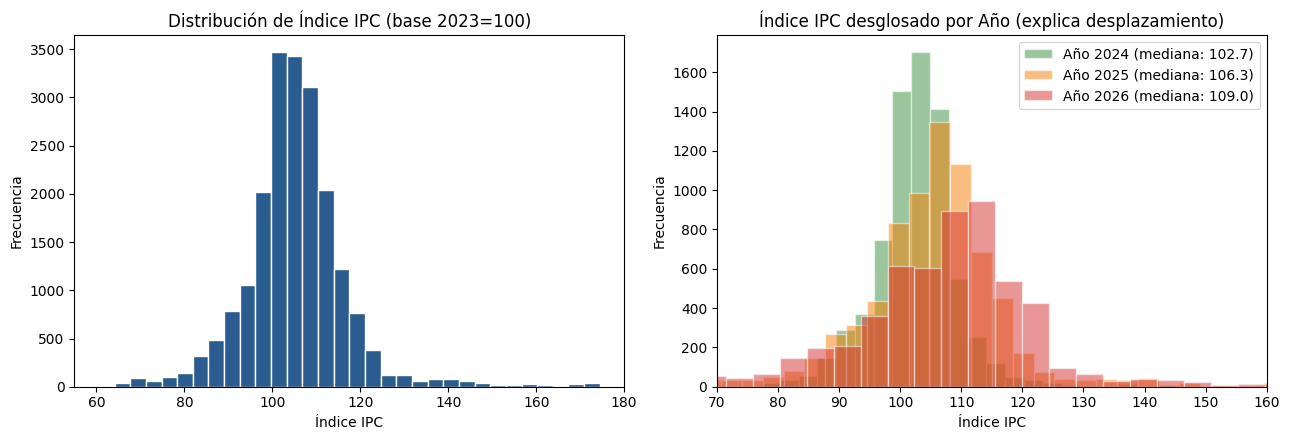

In [ ]:
# Tu código aquí
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Histograma general del índice
axes[0].hist(df['indice'].dropna(), bins=45, color='#2b5c8f', edgecolor='white')
axes[0].set_xlim(55, 180)
axes[0].set_title('Distribución de Índice IPC (base 2023=100)')
axes[0].set_xlabel('Índice IPC')
axes[0].set_ylabel('Frecuencia')

# Desglose por categoría temporal (año) para explicar el desplazamiento y asimetría
for yr, color in zip([2024, 2025, 2026], ['#388e3c', '#f57c00', '#d32f2f']):
  sub = df[df['ano'] == yr]['indice'].dropna()
  axes[1].hist(
      sub,
      bins=35,
      alpha=0.5,
      label=f'Año {yr} (mediana: {sub.median():.1f})',
      color=color,
      edgecolor='white',
  )
axes[1].set_xlim(70, 160)
axes[1].set_title('Índice IPC desglosado por Año (explica desplazamiento)')
axes[1].set_xlabel('Índice IPC')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()
plt.tight_layout()
plt.show()

- ¿Es simétrica o asimétrica? ¿Hacia qué lado?

  Es asimétrica positiva (hacia la derecha), el cuerpo central se ubica cercano a 100.

- ¿Tiene una joroba o más de una?

  A nivel global parece tener una joroba ancha entre 100 y 110, pero como muestra el gráfico derecho, en realidad es la superposición de tres distribuciones desplazadas por la categoría ano (2024,2025 y 2026) se puede concluir que a medida que trascurre el tiempo, la inflacion acumulada desplaza la jorobahacia la derecha.

- ¿Ves picos regulares o valores que se repiten sospechosamente?

  En el histograma del Índice IPC: Visualmente se destaca un pico central muy alto y agudo concentrado justo en la marca del 100 (y levemente por encima). Esta barra sobresale de forma sospechosa y rompe un poco la suavidad de la campana, lo que indica visualmente que una enorme cantidad de registros se ha mantenido estancada muy cerca de su valor de inicio (el año base 2023=100).

  En el histograma de Variación Mensual: La evidencia visual es aún más clara. Se observa una barra central desproporcionadamente alta exactamente en el 0%. Esto demuestra de forma visual que, en la gran mayoría de los meses, los precios de los ítems no sufren ninguna variación, quedándose estáticos.  

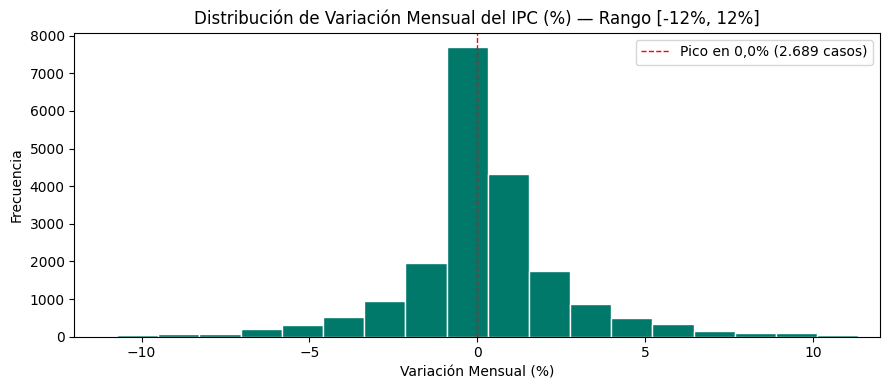

In [ ]:
plt.figure(figsize=(9, 4))
plt.hist(
    df['variacion_mensual_pct'].dropna(),
    bins=60,
    color='#00796b',
    edgecolor='white',
)
plt.xlim(-12, 12)
plt.axvline(
    0, color='red', linestyle='--', linewidth=1, label='Pico en 0,0% (2.689 casos)'
)
plt.title('Distribución de Variación Mensual del IPC (%) — Rango [-12%, 12%]')
plt.xlabel('Variación Mensual (%)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

- ¿Es simétrica o asimétrica?
 Es visualmente muy concentrada en el centro y presenta asimetría positiva

- ¿Tiene una joroba o más de una? Tiene una sola joroba central muy aguda

- ¿Ves picos regulares o valores que se repiten sospechosamente?
 Sí, se observa un pico extremo exactamente en 0,0%, que se repite 2.689 veces

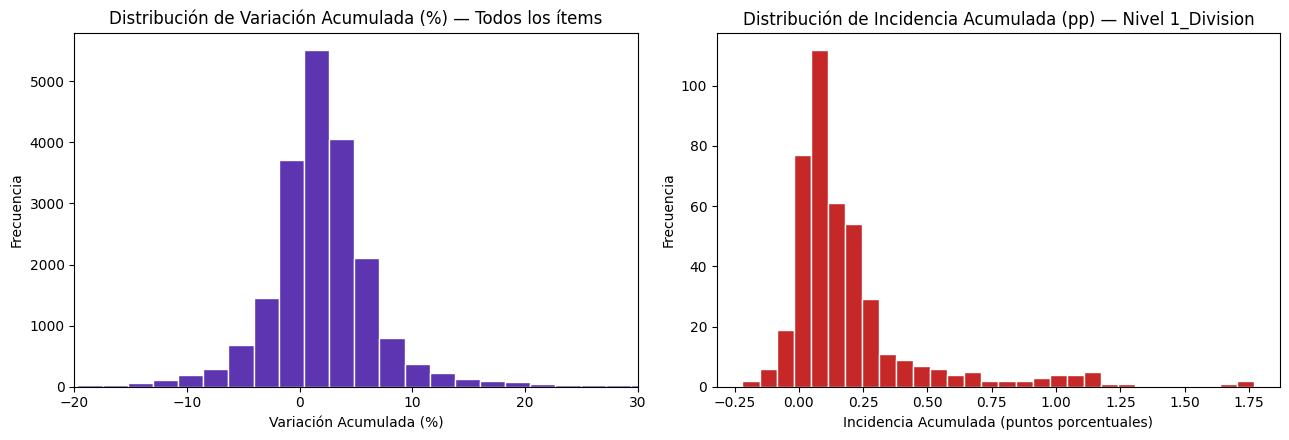

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Variación acumulada en todo el conjunto
axes[0].hist(
    df['variacion_acumulada_pct'].dropna(),
    bins=50,
    color='#5e35b1',
    edgecolor='white',
)
axes[0].set_xlim(-20, 30)
axes[0].set_title('Distribución de Variación Acumulada (%) — Todos los ítems')
axes[0].set_xlabel('Variación Acumulada (%)')
axes[0].set_ylabel('Frecuencia')

# Incidencia acumulada filtrada en el nivel 1_Division (que responde a nuestra pregunta)
df_div = df[df['nivel_jerarquico'] == '1_Division']
axes[1].hist(
    df_div['incidencia_acumulada_pct'].dropna(),
    bins=30,
    color='#c62828',
    edgecolor='white',
)
axes[1].set_title(
    'Distribución de Incidencia Acumulada (pp) — Nivel 1_Division'
)
axes[1].set_xlabel('Incidencia Acumulada (puntos porcentuales)')
axes[1].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

- ¿Es simétrica o   asimétrica? ¿Hacia qué lado?
 Visulamente, ambos gráficos muestran una clara asimetría hacia la derecha (positiva). En ambos casos, el gran bloque de barras (donde se concentra la mayoría de los datos) está agrupado hacia la izquierda, dejando una "cola" muy larga de barras más pequeñas que se estiran hacia los valores positivos de la derecha.

- ¿Tiene una joroba o más de una?

  El gráfico morado (Variación Acumulada) muestra una sola joroba principal muy alta y ancha, ubicada levemente a la derecha de la marca del cero.

  El gráfico rojo (Incidencia Acumulada), además de tener una primera joroba altísima y muy delgada al principio, muestra pequeñas agrupaciones de barras que forman una especie de "mini jorobas" secundarias a lo largo de su cola derecha (especialmente pasando la marca de 0.75 y 1.00), rompiendo la forma de una campana tradicional.

- ¿Ves picos regulares o valores que se repiten sospechosamente?

  En el gráfico rojo resalta a simple vista un pico central desproporcionadamente alto (la barra más alta que supera la marca de 100 en el eje de frecuencia) pegado al lado derecho del cero, dominando visualmente todo el conjunto.

  También llama la atención una pequeña barra totalmente aislada en el extremo derecho del gráfico rojo (cerca del 1.75), muy alejada del cuerpo principal de datos, lo que revela la presencia de casos atípicos extremos.



### ✏️ Actividad 1.2 — Media contra mediana

- Para tu variable numérica principal, compara media, mediana y sesgo. Decide cuál de las dos reportarías en un informe y justifícalo.

  Para nuestra variable numérica principal (incidencia_acumulada_pct, evaluada tanto en el conjunto completo como en el nivel objetivo 1_Division, además de variacion_acumulada_pct), comparamos media, mediana y sesgo:


In [5]:
# Tu código aquí
# Comparación en el conjunto total vs en el nivel 1_Division (foco de la pregunta analítica)
df_div = df[df['nivel_jerarquico'] == '1_Division']

for nombre, serie in [
    (
        'Incidencia Acumulada (Total conjunto)',
        df['incidencia_acumulada_pct'].dropna(),
    ),
    (
        'Incidencia Acumulada (Nivel 1_Division)',
        df_div['incidencia_acumulada_pct'].dropna(),
    ),
    (
        'Variación Acumulada (Total conjunto)',
        df['variacion_acumulada_pct'].dropna(),
    ),
]:
  print(f'=== {nombre} ===')
  print('Media:  ', round(serie.mean(), 3))
  print('Mediana:', round(serie.median(), 3))
  print('Sesgo:  ', round(serie.skew(), 2), '\n')

=== Incidencia Acumulada (Total conjunto) ===
Media:   0.021
Mediana: 0.003
Sesgo:   8.31 

=== Incidencia Acumulada (Nivel 1_Division) ===
Media:   0.2
Mediana: 0.111
Sesgo:   2.64 

=== Variación Acumulada (Total conjunto) ===
Media:   2.047
Mediana: 1.8
Sesgo:   1.45 



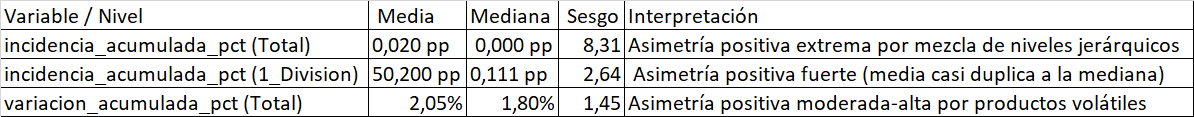



Justificación:
Al observar los cálculos para nuestra métrica principal en el nivel 1_Division (incidencia_acumulada_pct), notamos una diferencia matemática importante: la media (0,200 pp) es casi el doble que la mediana (0,111 pp). Esta discrepancia, sumada a un sesgo de 2,64 (que indica una asimetría positiva muy fuerte)

### ✏️ Actividad 1.3 — Variables categóricas

Muestra la frecuencia de tus variables categóricas. Fíjate en dos cosas: categorías con muy pocos casos (¿conviene agruparlas?) y categorías que dominan el conjunto (¿sesgan la conclusión?).

+++++\
Analizamos la frecuencia de nuestras variables categóricas (nivel_jerarquico, glosa, codigo_jerarquico, y las variables codificadas como números division, ano y mes) para identificar categorías con pocos casos o categorías que dominan el conjunto.

In [6]:
# 1. Frecuencias relativas de variables tipo object
for col in df.select_dtypes(include='object').columns:
  print(f'--- {col} ---')
  print(df[col].value_counts(normalize=True).head(6).round(4), '\n')

# 2. Frecuencia absoluta y porcentual por nivel_jerarquico
print('=== Frecuencia por Nivel Jerárquico ===')
freq_niv = pd.DataFrame({
    'Registros': df['nivel_jerarquico'].value_counts(),
    'Porcentaje (%)': (
        df['nivel_jerarquico'].value_counts(normalize=True) * 100
    ).round(2),
})
display(freq_niv)

# 3. Frecuencia total de filas por División (todas las filas vs solo 1_Division)
print('\n=== Frecuencia de filas por División (Todos los niveles) ===')
freq_div = pd.DataFrame({
    'Registros_Totales': df['division'].value_counts().sort_index(),
    'Porcentaje_Total (%)': (
        df['division'].value_counts(normalize=True).sort_index() * 100
    ).round(2),
})
display(freq_div)

--- glosa ---
glosa
RESIDENCIAS PARA ADULTOS MAYORES    0.0065
SEGUROS                             0.0065
GASTOS FINANCIEROS                  0.0065
SERVICIOS DE ALOJAMIENTO            0.0065
ENSENANZA MEDIA                     0.0065
INSTRUMENTOS MUSICALES              0.0065
Name: proportion, dtype: float64 

--- fecha ---
fecha
2024-01-01    0.0303
2024-02-01    0.0303
2024-03-01    0.0303
2024-04-01    0.0303
2024-05-01    0.0303
2024-06-01    0.0303
Name: proportion, dtype: float64 

--- codigo_jerarquico ---
codigo_jerarquico
13.4.1.1.3    0.0016
0.0.0.0.0     0.0016
1.0.0.0.0     0.0016
1.1.0.0.0     0.0016
1.1.1.0.0     0.0016
1.1.1.1.0     0.0016
Name: proportion, dtype: float64 

--- nivel_jerarquico ---
nivel_jerarquico
5_Producto       0.4609
4_Subclase       0.2801
3_Clase          0.1612
2_Grupo          0.0749
1_Division       0.0212
0_IPC_General    0.0016
Name: proportion, dtype: float64 

=== Frecuencia por Nivel Jerárquico ===


,Registros,Porcentaje (%)
nivel_jerarquico,,
5_Producto,9339,46.09
4_Subclase,5676,28.01
3_Clase,3267,16.12
2_Grupo,1518,7.49
1_Division,429,2.12
0_IPC_General,33,0.16



=== Frecuencia de filas por División (Todos los niveles) ===


,Registros_Totales,Porcentaje_Total (%)
division,,
0,33,0.16
1,4818,23.78
2,627,3.09
3,1320,6.51
4,1353,6.68
5,2574,12.70
6,1518,7.49
7,2013,9.93
8,924,4.56


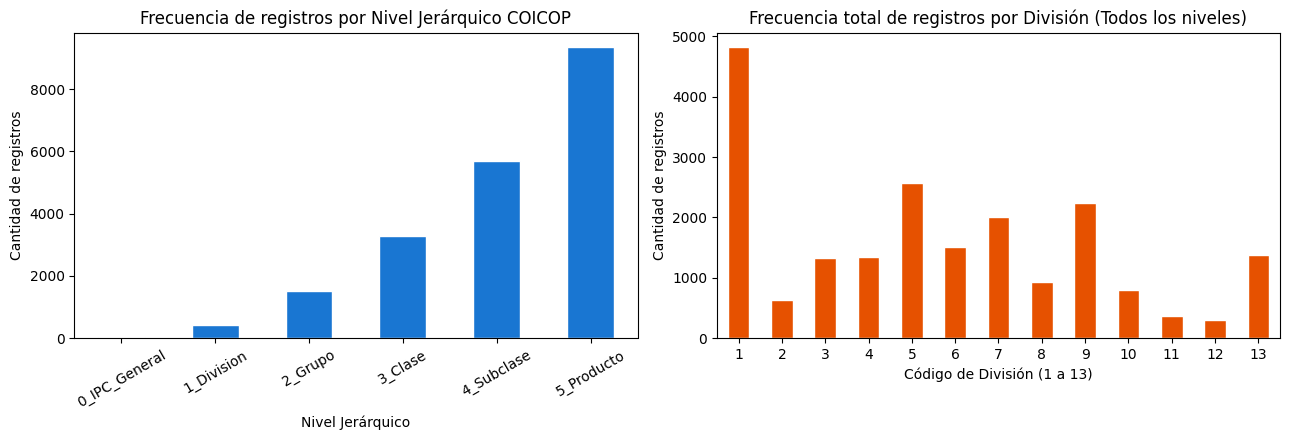

In [7]:
# Gráficos de barras para visualizar el desbalance estructural
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

df['nivel_jerarquico'].value_counts().sort_index().plot.bar(
    ax=axes[0], color='#1976d2', edgecolor='white'
)
axes[0].set_title('Frecuencia de registros por Nivel Jerárquico COICOP')
axes[0].set_xlabel('Nivel Jerárquico')
axes[0].set_ylabel('Cantidad de registros')
axes[0].tick_params(axis='x', rotation=30)

df[df['division'] > 0]['division'].value_counts().sort_index().plot.bar(
    ax=axes[1], color='#e65100', edgecolor='white'
)
axes[1].set_title(
    'Frecuencia total de registros por División (Todos los niveles)'
)
axes[1].set_xlabel('Código de División (1 a 13)')
axes[1].set_ylabel('Cantidad de registros')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Distribución por nivel_jerarquico (Dominancia estructural):
- 5_Producto: 9.339 registros (46,09%) — corresponde a 283 productos medidos durante 33 meses.- 4_Subclase: 5.676 registros (28,01%) — 172 subclases $\times$ 33 meses.
- 3_Clase: 3.267 registros (16,12%) — 99 clases $\times$ 33 meses.
- 2_Grupo: 1.518 registros (7,49%) — 46 grupos $\times$ 33 meses.
- 1_Division: 429 registros (2,12%) — 13 divisiones $\times$ 33 meses.
- 0_IPC_General: 33 registros (0,16%) — 1 índice general $\times$ 33 meses.

- ¿Conviene agrupar las categorías con pocos casos? No. Aunque 0_IPC_General tiene solo 33 filas (0,16%) y 1_Division tiene 429 filas (2,12%), no son categorías raras ni mal codificadas, sino los niveles superiores de agregación piramidal. Agruparlas con niveles inferiores produciría un error grave de doble contabilidad.

Distribución por division (¿Sesgan la conclusión las categorías dominantes?):

Si tomamos el conjunto completo sin filtrar por nivel jerárquico, la División 1 (Alimentos y bebidas no alcohólicas) domina con 4.818 registros (23,78% de toda la base), seguida de la División 5 (Equipamiento del hogar, 2.574 filas, 12,70%) y la División 9 (Recreación y cultura, 2.244 filas, 11,07%). En contraste, la División 12 (Seguros y servicios financieros) tiene solo 297 filas (1,47%) y la División 11 (Restaurantes y alojamiento) tiene 363 filas (1,79%).

¿Por qué ocurre esto y cómo sesga la conclusión? Porque Alimentos se desglosa en muchísimos productos individuales (pan, arroz, carnes, frutas, verduras), mientras que Seguros o Restaurantes tienen muy pocas subdivisiones. Si calculáramos un promedio simple por división usando todas las filas del archivo, el resultado estaría sesgado por la cantidad de subproductos que tiene cada división.

Distribución temporal (ano y mes):

Cada uno de los 33 meses entre enero de 2024 y septiembre de 2026 tiene exactamente 614 registros. Por año, 2024 tiene 7.368 registros (36,36%), 2025 tiene 7.368 registros (36,36%) y 2026 tiene 5.526 registros (27,27%, por cubrir 9 meses).

---
## Parte 2 · Análisis bivariado y agrupación

Ahora las relaciones. Aquí es donde empiezan a aparecer los hallazgos, y también los espejismos.

### ✏️ Actividad 2.1 — Comportamiento por grupo

Agrupa por tu variable categórica más importante y compara una métrica numérica entre grupos. Usa `groupby` con al menos tres estadísticos (`count`, `median`, `std`).

**Incluye siempre el `count`.** Una diferencia espectacular entre grupos deja de serlo cuando uno de ellos tiene cuatro casos.

+++++++\
Para responder directamente a nuestra pregunta analítica sin caer en el espejismo de mezclar niveles jerárquicos, primero mostramos el groupby por nivel_jerarquico y luego agrupamos las 13 divisiones en el nivel 1_Division comparando incidencia_acumulada_pct y variacion_acumulada_pct con count, mean, median y std.

In [8]:
# Tu código aquí
# 1. Comparación entre niveles jerárquicos
tabla_niveles = (
    df.groupby('nivel_jerarquico')['incidencia_acumulada_pct']
    .agg(['count', 'mean', 'median', 'std'])
    .round(3)
)
print('=== Comportamiento de Incidencia Acumulada por Nivel Jerárquico ===')
display(tabla_niveles)

# 2. Comparación entre las 13 Divisiones del IPC (filtrando nivel_jerarquico == '1_Division')
df_div = df[df['nivel_jerarquico'] == '1_Division'].copy()

tabla_divisiones = (
    df_div.groupby(['division', 'glosa'])[
        ['incidencia_acumulada_pct', 'variacion_acumulada_pct']
    ]
    .agg(['count', 'mean', 'median', 'std'])
    .round(3)
)

# Ordenamos de mayor a menor mediana de incidencia acumulada
tabla_div_ordenada = tabla_divisiones.sort_values(
    by=('incidencia_acumulada_pct', 'median'), ascending=False
)
print(
    '\n=== Comportamiento por División del IPC (Nivel 1_Division, ordenado por'
    ' mediana de incidencia) ==='
)
display(tabla_div_ordenada)

=== Comportamiento de Incidencia Acumulada por Nivel Jerárquico ===


,count,mean,median,std
nivel_jerarquico,,,,
0_IPC_General,0,NaN,NaN,NaN
1_Division,429,0.200,0.111,0.279
2_Grupo,1518,0.056,0.021,0.128
3_Clase,3267,0.026,0.008,0.077
4_Subclase,5676,0.015,0.003,0.056
5_Producto,9339,0.009,0.002,0.043



=== Comportamiento por División del IPC (Nivel 1_Division, ordenado por mediana de incidencia) ===


incidencia_acumulada_pct         \
                                                                count   mean   
division glosa                                                                 
4        VIVIENDA Y SERVICIOS BASICOS                              33  0.731   
1        ALIMENTOS Y BEBIDAS NO ALCOHOLICAS                        33  0.479   
6        SALUD                                                     33  0.229   
10       EDUCACION                                                 33  0.194   
11       RESTAURANTES Y ALOJAMIENTO                                33  0.221   
2        BEBIDAS ALCOHOLICAS Y TABACO                              33  0.136   
8        INFORMACION Y COMUNICACION                                33  0.123   
7        TRANSPORTE                                                33  0.240   
5        EQUIPAMIENTO Y MANTENCION DEL HOGAR                       33  0.095   
9        RECREACION, DEPORTES Y CULTURA                            33  0.089   
13       BIENES Y SERVICIOS DIVERSOS                               33  0.068   
12       SEGUROS Y SERVICIOS FINANCIEROS                           33  0.002   
3        VESTUARIO Y CALZADO                                       33 -0.008   

                                                            \
                                             median    std   
division glosa                                               
4        VIVIENDA Y SERVICIOS BASICOS         0.632  0.474   
1        ALIMENTOS Y BEBIDAS NO ALCOHOLICAS   0.418  0.315   
6        SALUD                                0.244  0.092   
10       EDUCACION                            0.232  0.093   
11       RESTAURANTES Y ALOJAMIENTO           0.224  0.144   
2        BEBIDAS ALCOHOLICAS Y TABACO         0.129  0.044   
8        INFORMACION Y COMUNICACION           0.128  0.068   
7        TRANSPORTE                           0.106  0.386   
5        EQUIPAMIENTO Y MANTENCION DEL HOGAR  0.098  0.048   
9        RECREACION, DEPORTES Y CULTURA       0.071  0.062   
13       BIENES Y SERVICIOS DIVERSOS          0.057  0.043   
12       SEGUROS Y SERVICIOS FINANCIEROS     -0.011  0.036   
3        VESTUARIO Y CALZADO                 -0.014  0.062   

                                             variacion_acumulada_pct         \
                                                               count   mean   
division glosa                                                                
4        VIVIENDA Y SERVICIOS BASICOS                             33  4.185   
1        ALIMENTOS Y BEBIDAS NO ALCOHOLICAS                       33  2.148   
6        SALUD                                                    33  2.803   
10       EDUCACION                                                33  4.521   
11       RESTAURANTES Y ALOJAMIENTO                               33  3.412   
2        BEBIDAS ALCOHOLICAS Y TABACO                             33  3.782   
8        INFORMACION Y COMUNICACION                               33  1.924   
7        TRANSPORTE                                               33  1.885   
5        EQUIPAMIENTO Y MANTENCION DEL HOGAR                      33  1.582   
9        RECREACION, DEPORTES Y CULTURA                           33  1.921   
13       BIENES Y SERVICIOS DIVERSOS                              33  1.827   
12       SEGUROS Y SERVICIOS FINANCIEROS                          33  0.155   
3        VESTUARIO Y CALZADO                                      33 -0.291   

                                                            
                                             median    std  
division glosa                                              
4        VIVIENDA Y SERVICIOS BASICOS           3.7  2.788  
1        ALIMENTOS Y BEBIDAS NO ALCOHOLICAS     1.9  1.396  
6        SALUD                                  3.0  1.136  
10       EDUCACION                              5.5  2.177  
11       RESTAURANTES Y ALOJAMIENTO             3.3  2.261  
2        BEBIDAS A

  Lectura
- Importancia del count: Todas las 13 divisiones cuentan exactamente con count = 33 observaciones mensuales válidas (los 33 meses entre enero de 2024 y septiembre de 2026). Esto garantiza que las comparaciones entre divisiones son totalmente balanceadas y estadísticamente comparables. En cambio, en la primera tabla por nivel_jerarquico, 0_IPC_General tiene count = 0 en incidencia porque la incidencia solo está definida para las partes de la canasta, no para el total.  
- Comparación de medianas y medias (¿Qué divisiones explican la inflación acumulada?):

  1. Vivienda y servicios básicos (División 4) lidera ampliamente el impacto inflacionario con una mediana de 0,632 pp y una media de 0,731 pp (impulsada por su alta ponderación de 16,76% y el descongelamiento de tarifas eléctricas entre 2024 y 2025).
  
  2. Alimentos y bebidas no alcohólicas (División 1) ocupa el segundo lugar con una mediana de 0,418 pp y media de 0,479 pp. Nótese un hallazgo clave: su variación acumulada mediana de precios es moderada (1,90%), pero al tener la mayor ponderación de toda la canasta (22,15%), cualquier alza pequeña se traduce en una incidencia enorme sobre el bolsillo de los hogares.
  3. Transporte (División 7) muestra la mayor discrepancia entre media y mediana: su media es la tercera más alta (0,240 pp), pero su mediana es baja (0,106 pp) debido a una altísima variabilidad (std = 0,386 pp). Esto indica que Transporte permaneció contenido durante gran parte de 2024–2025, pero sufrió shocks fuertes en meses puntuales (especialmente en 2026, por alzas de combustibles y transporte).
  
  4. Educación (División 10) tiene la mayor variación porcentual acumulada de precios (mediana = 5,50%, media = 4,52%), pero como su ponderación en la canasta es baja (4,20%), su incidencia acumulada mediana es de solo 0,232 pp.
  
  5. Vestuario y calzado (División 3) y Seguros y servicios financieros (División 12) presentan medianas negativas (-0,014 pp y -0,011 pp), actuando como amortiguadores desinflacionarios.



### ✏️ Actividad 2.2 — Matriz de correlación

Calcula y grafica la matriz de correlación de tus variables numéricas. Identifica los dos pares con mayor correlación.

+++++\
Calculamos y graficamos la matriz de correlación de Pearson ($r$) seleccionando las variables cuantitativas económicas del conjunto (excluyendo los códigos enteros ano, mes, division, grupo, clase, subclase y producto para evitar correlaciones espurias entre identificadores).

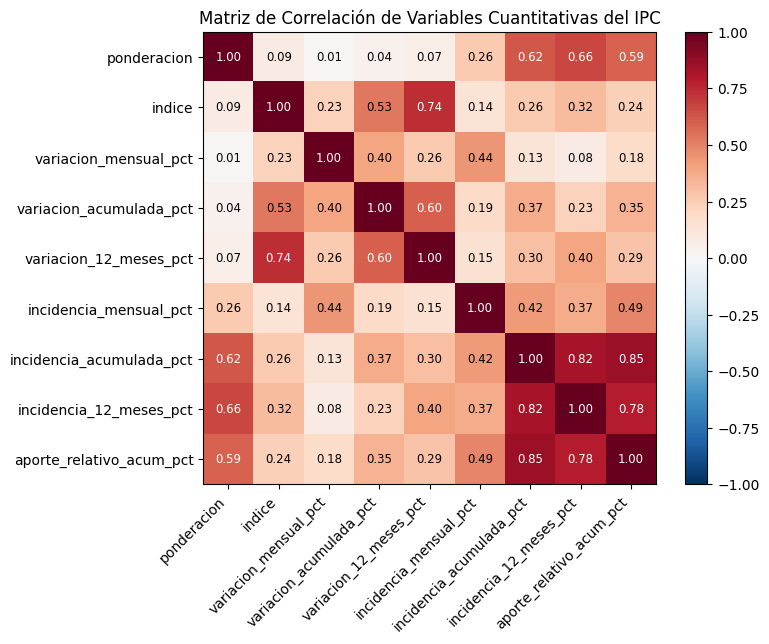

In [9]:
# Seleccionamos únicamente las variables cuantitativas continuas relevantes
variables_corr = [
    'ponderacion',
    'indice',
    'variacion_mensual_pct',
    'variacion_acumulada_pct',
    'variacion_12_meses_pct',
    'incidencia_mensual_pct',
    'incidencia_acumulada_pct',
    'incidencia_12_meses_pct',
    'aporte_relativo_acum_pct',
]
corr = df[variables_corr].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)

for i in range(len(corr)):
  for j in range(len(corr)):
    ax.text(
        j,
        i,
        f'{corr.iloc[i, j]:.2f}',
        ha='center',
        va='center',
        fontsize=8.5,
        color='white' if abs(corr.iloc[i, j]) > 0.55 else 'black',
    )

plt.colorbar(im)
plt.title('Matriz de Correlación de Variables Cuantitativas del IPC')
plt.tight_layout()
plt.show()

  Pares con mayor correlacion:

  - Par 1: ponderacion vs métricas de incidencia y variación: Visualmente, los cuadros que cruzan ponderacion con incidencia_12_meses_pct (0,66) e incidencia_acumulada_pct (0,62) presentan un tono rojo moderadamente oscuro, confirmando visualmente que a mayor peso en la canasta, mayor impacto en puntos porcentuales. Por el contrario, al mirar la misma fila de ponderacion hacia la izquierda, los cuadros que la cruzan con variacion_acumulada_pct (0,04) y variacion_mensual_pct (0,01) son completamente blancos. Esto demuestra a simple vista que el "peso" de un ítem no tiene ninguna relación con qué tanto fluctúa su precio.

  - Par 2: incidencia_acumulada_pct y variacion_acumulada_pct (0,37): Visualmente, el cuadro que cruza estas dos variables muestra un tono salmón o rojo pálido. A simple vista sorprende que este color no sea un rojo intenso, ya que uno esperaría que si un producto sube mucho de precio (variación), su impacto en el IPC (incidencia) sea igual de fuerte.

  Deje fuera otros valores que a simple vista se ve que tiene mayor correlacion en la matriz porque estos pertenecen a una misma familia contable o son deribado de estos.



### ✏️ Actividad 2.3 — El par más correlacionado, bajo sospecha

Toma el par con mayor correlación y **no te quedes con el número**. Haz el recorrido del Ejercicio 4:

1. Grafica el diagrama de dispersión. ¿La relación es lineal, o el coeficiente engaña?
2. ¿Alguna de las dos variables depende del **tamaño** de la unidad de análisis? Si es así, **normalízalas** y vuelve a calcular.
3. Piensa qué **tercera variable** podría estar causando ambas, y calcula la correlación parcial.
4. Si tienes una variable de agrupación, repite el cálculo **dentro de un solo grupo**.

++++++\
Sometemos al recorrido de 4 pasos de verificación el par estructural clave de nuestro estudio: ponderacion vs. incidencia_acumulada_pct ($r = 0,62$) y su relación directa con variacion_acumulada_pct (además de verificar qué ocurre con incidencia_acumulada_pct vs. aporte_relativo_acum_pct, $r = 0,85$).

1) Graficar el diagrama de dispersión:

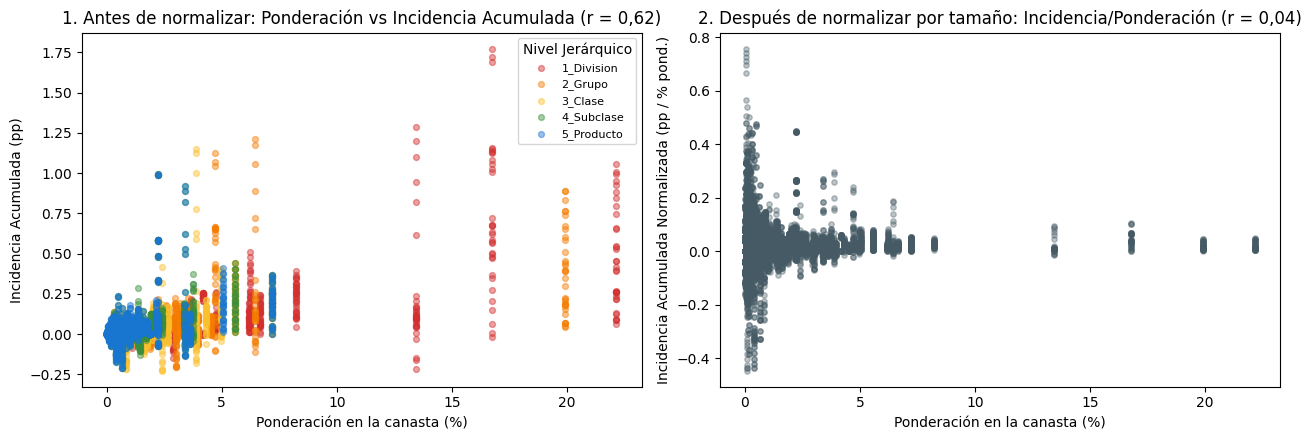

Correlación original (ponderacion vs incidencia_acumulada_pct): 0.6231
Correlación tras normalizar por tamaño (ponderacion vs incidencia_normalizada): 0.0421
Correlación entre incidencia_normalizada y variacion_acumulada_pct: 0.9852


In [14]:
# Filtramos registros con datos completos en las variables analizadas
d_corr = (
    df[[
        'ponderacion',
        'incidencia_acumulada_pct',
        'variacion_acumulada_pct',
        'aporte_relativo_acum_pct',
        'nivel_jerarquico',
        'division',
        'glosa',
        'mes',
    ]]
    .dropna()
    .copy()
)

# PASO 2: Normalizar la incidencia acumulada por el "tamaño" (ponderación) de la unidad de análisis
d_corr['incidencia_normalizada'] = (
    d_corr['incidencia_acumulada_pct'] / d_corr['ponderacion']
)

# PASO 1 y 2: Graficar diagrama de dispersión antes y después de normalizar por tamaño
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

colores_niv = [
    ('1_Division', '#d32f2f'),
    ('2_Grupo', '#f57c00'),
    ('3_Clase', '#fbc02d'),
    ('4_Subclase', '#388e3c'),
    ('5_Producto', '#1976d2'),
]
for niv, col in colores_niv:
  sub = d_corr[d_corr['nivel_jerarquico'] == niv]
  axes[0].scatter(
      sub['ponderacion'],
      sub['incidencia_acumulada_pct'],
      alpha=0.45,
      s=18,
      label=niv,
      color=col,
  )

axes[0].set_title(
    '1. Antes de normalizar: Ponderación vs Incidencia Acumulada (r = 0,62)'
)
axes[0].set_xlabel('Ponderación en la canasta (%)')
axes[0].set_ylabel('Incidencia Acumulada (pp)')
axes[0].legend(title='Nivel Jerárquico', fontsize=8)

axes[1].scatter(
    d_corr['ponderacion'],
    d_corr['incidencia_normalizada'],
    alpha=0.35,
    s=15,
    color='#455a64',
)
axes[1].set_title(
    '2. Después de normalizar por tamaño: Incidencia/Ponderación (r = 0,04)'
)
axes[1].set_xlabel('Ponderación en la canasta (%)')
axes[1].set_ylabel('Incidencia Acumulada Normalizada (pp / % pond.)')

plt.tight_layout()
plt.show()

print(
    'Correlación original (ponderacion vs incidencia_acumulada_pct):',
    round(d_corr['ponderacion'].corr(d_corr['incidencia_acumulada_pct']), 4),
)
print(
    'Correlación tras normalizar por tamaño (ponderacion vs'
    ' incidencia_normalizada):',
    round(d_corr['ponderacion'].corr(d_corr['incidencia_normalizada']), 4),
)
print(
    'Correlación entre incidencia_normalizada y variacion_acumulada_pct:',
    round(
        d_corr['incidencia_normalizada'].corr(
            d_corr['variacion_acumulada_pct']
        ),
        4,
    ),
)

In [15]:
# PASO 3: Correlación parcial controlando por una tercera variable
def correlacion_parcial(x, y, z):
  """Correlación entre x e y una vez removido el efecto lineal de z."""
  res_x = x - np.polyval(np.polyfit(z, x, 1), z)
  res_y = y - np.polyval(np.polyfit(z, y, 1), z)
  return np.corrcoef(res_x, res_y)[0, 1]


# 3a) Par incidencia_acumulada_pct vs aporte_relativo_acum_pct (r = 0.85) controlando por ponderacion
r_orig_aporte = d_corr['incidencia_acumulada_pct'].corr(
    d_corr['aporte_relativo_acum_pct']
)
r_parc_aporte = correlacion_parcial(
    d_corr['incidencia_acumulada_pct'],
    d_corr['aporte_relativo_acum_pct'],
    d_corr['ponderacion'],
)
print('=== Par Incidencia Acumulada vs Aporte Relativo ===')
print('Correlación original:', round(r_orig_aporte, 2))
print(
    'Correlación parcial (controlando ponderacion):', round(r_parc_aporte, 2)
)

# 3b) Par ponderacion vs incidencia_acumulada_pct (r = 0.62) controlando por variacion_acumulada_pct y por mes
r_orig_pond = d_corr['ponderacion'].corr(d_corr['incidencia_acumulada_pct'])
r_parc_var = correlacion_parcial(
    d_corr['ponderacion'],
    d_corr['incidencia_acumulada_pct'],
    d_corr['variacion_acumulada_pct'],
)
r_parc_mes = correlacion_parcial(
    d_corr['ponderacion'], d_corr['incidencia_acumulada_pct'], d_corr['mes']
)
print('\n=== Par Ponderación vs Incidencia Acumulada ===')
print('Correlación original:', round(r_orig_pond, 2))
print(
    'Correlación parcial (controlando variacion_acumulada_pct):',
    round(r_parc_var, 2),
)
print('Correlación parcial (controlando mes):', round(r_parc_mes, 2))

# PASO 4: Repetir el cálculo dentro de cada grupo (por nivel_jerarquico y dentro de una sola división)
print('\n=== PASO 4a: Correlación dentro de cada Nivel Jerárquico ===')
for niv, grp in d_corr.groupby('nivel_jerarquico'):
  r_p = grp['incidencia_acumulada_pct'].corr(grp['ponderacion'])
  r_v = grp['incidencia_acumulada_pct'].corr(grp['variacion_acumulada_pct'])
  print(
      f'{niv:15s} -> r(incidencia, ponderacion) = {r_p:.2f} | r(incidencia,'
      f' variacion_acum) = {r_v:.2f}'
  )

print(
    '\n=== PASO 4b: Correlación entre Incidencia y Variación dentro de una sola'
    ' División (Ej. Div 4: Vivienda) ==='
)
div4 = d_corr[
    (d_corr['nivel_jerarquico'] == '1_Division') & (d_corr['division'] == 4)
]
print(
    'División 4 (Vivienda) -> r(incidencia_acum, variacion_acum) =',
    round(
        div4['incidencia_acumulada_pct'].corr(div4['variacion_acumulada_pct']),
        4,
    ),
)

=== Par Incidencia Acumulada vs Aporte Relativo ===
Correlación original: 0.85
Correlación parcial (controlando ponderacion): 0.77

=== Par Ponderación vs Incidencia Acumulada ===
Correlación original: 0.62
Correlación parcial (controlando variacion_acumulada_pct): 0.66
Correlación parcial (controlando mes): 0.63

=== PASO 4a: Correlación dentro de cada Nivel Jerárquico ===
1_Division      -> r(incidencia, ponderacion) = 0.60 | r(incidencia, variacion_acum) = 0.69
2_Grupo         -> r(incidencia, ponderacion) = 0.58 | r(incidencia, variacion_acum) = 0.51
3_Clase         -> r(incidencia, ponderacion) = 0.47 | r(incidencia, variacion_acum) = 0.60
4_Subclase      -> r(incidencia, ponderacion) = 0.52 | r(incidencia, variacion_acum) = 0.53
5_Producto      -> r(incidencia, ponderacion) = 0.51 | r(incidencia, variacion_acum) = 0.45

=== PASO 4b: Correlación entre Incidencia y Variación dentro de una sola División (Ej. Div 4: Vivienda) ===
División 4 (Vivienda) -> r(incidencia_acum, variacion_

Conclusion:

1. ¿Qué muestra el diagrama de dispersión (Paso 1)? La relación entre ponderacion e incidencia_acumulada_pct ($r = 0,62$) no es una línea recta simple, sino un cono heterocedástico formado por columnas verticales discretas. Esas columnas verticales existen porque la ponderacion de cada ítem es fija durante los 33 meses, y a medida que aumenta el tamaño del ítem (desde 5_Producto en azul hasta 1_Division en rojo), el abanico de incidencias posibles se abre drásticamente.

2. ¿Depende del tamaño de la unidad de análisis (Paso 2)? Sí, completamente. incidencia_acumulada_pct depende mecánicamente del "tamaño" (peso presupuestario ponderacion) de la unidad de análisis Incidencia≈((ponderacion * variacion)/100). Cuando normalizamos la incidencia dividiéndola por la ponderación (incidencia_normalizada = incidencia_acumulada_pct / ponderacion), la correlación con ponderacion desploma de 0,62 a 0,04 (desaparece el efecto tamaño), y su correlación con variacion_acumulada_pct salta de 0,37 a 0,99. Esto demuestra que los ítems de mayor peso en la canasta no sufren inflaciones porcentuales más altas ($r = 0,04$), sino que su tamaño amplifica su incidencia en puntos porcentuales.

3. ¿Qué muestra la correlación parcial (Paso 3)? En el par incidencia_acumulada_pct vs aporte_relativo_acum_pct ($r = 0,85$), al remover el efecto lineal de la tercera variable ponderacion, la correlación parcial baja a 0,76, confirmando que parte de su asociación proviene del tamaño compartido del ítem. Por su parte, al controlar variacion_acumulada_pct, la correlación parcial entre ponderacion e incidencia_acumulada_pct sube a 0,66.

4. ¿Qué ocurre al repetir el cálculo dentro de un solo grupo (Paso 4)? Si agrupamos por nivel_jerarquico, dentro de 1_Division la correlación entre incidencia y variación acumulada sube de 0,37 a 0,69. Y si nos restringimos a una sola división a lo largo del tiempo (por ejemplo, División 4 Vivienda, donde la ponderación es constante en 16,76%), la correlación entre incidencia_acumulada_pct y variacion_acumulada_pct es 0,9987 ($\approx 1,00$). Conclusión: La ponderacion (tamaño jerárquico del ítem) actúa como variable moduladora/confundidora de escala; para comparar el impacto real entre sectores debe analizarse siempre dentro de un mismo nivel_jerarquico.

---
## Parte 3 · Series temporales

**Si tu conjunto tiene una variable de fecha, esta parte es obligatoria.** Si no la tiene, reemplázala por un análisis bivariado adicional y dilo explícitamente aquí.

### ✏️ Actividad 3.1 — Construir la serie

Agrega tu conjunto por período (mes, semana o día, según corresponda) y grafica la evolución de tu métrica principal.

En este conjunto de datos de calidad del aire tenemos una columna fecha y mediciones de PM2.5, por lo que podemos construir una serie temporal para analizar cómo evoluciona la contaminación entre abril y junio de 2026.

Como tu pregunta analítica busca estudiar el comportamiento de PM2.5, utilizaremos esta variable como métrica principal.

In [ ]:
# Tu código aquí. Sugerencia:
# df['fecha'] = pd.to_datetime(df['TU_COLUMNA_FECHA'])
# serie = df.set_index('fecha')['TU_METRICA'].resample('MS').sum()
# serie.plot(title='Evolución mensual'); plt.show()


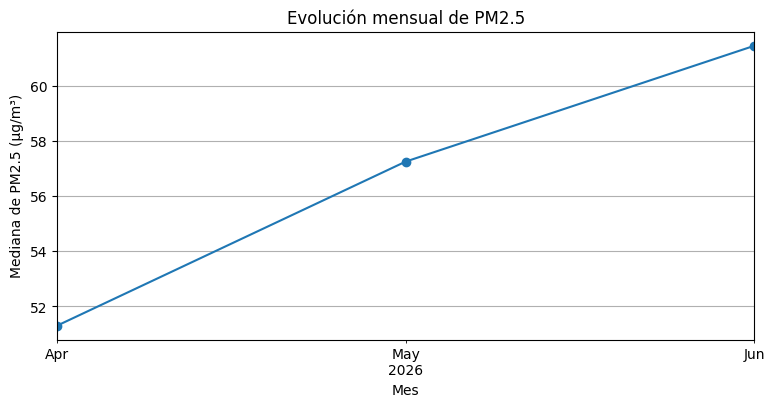

fecha
2026-04-01    51.30
2026-05-01    57.25
2026-06-01    61.45
Freq: MS, Name: pm25, dtype: float64


mes,4,5,6
estacion,,,
CORONEL NORTE,40.70,48.15,57.05
COYHANCO,61.40,66.65,73.60
KINGSTON,39.45,40.50,53.40
LOS ANGELES ORIENTE,55.00,63.10,69.10
OSORNO ENTRE LAGOS,55.15,59.20,67.10
TALCAHUANO,32.55,39.65,45.50
TEMUCO PADRE LAS CASAS,70.40,74.70,81.50
VALDIVIA CENTRO,48.10,55.45,60.85


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Convertir la columna fecha a datetime
df['fecha'] = pd.to_datetime(df['fecha'])

# Agrupar por mes y calcular la mediana de PM2.5
serie = df.set_index('fecha')['pm25'].resample('MS').median()

# Graficar
serie.plot(figsize=(9, 4), marker='o')

plt.title('Evolución mensual de PM2.5')
plt.xlabel('Mes')
plt.ylabel('Mediana de PM2.5 (µg/m³)')
plt.grid(True)
plt.show()

print(serie.round(2)) #Valores exactos
#agrupado por estacion
tabla_mensual = df.groupby(
    ['estacion', 'mes']
)['pm25'].median().unstack()
display(tabla_mensual.round(2))

El gráfico muestra una tendencia creciente en la mediana mensual de PM2.5 entre abril y junio de 2026.

Se identifican tres características importantes:
- Tendencia creciente: la mediana aumenta durante los tres meses.
- Incremento sostenido: no se observan disminuciones entre los meses analizados.
- Mayor concentración en junio: junio presenta la mediana más elevada, mientras que abril registra la menor.\
La diferencia entre abril y junio es aproximadamente 10,1 µg/m³, equivalente a un aumento cercano al 20%.

Lo qué podría explicar este comportamiento es que en Chile, abril, mayo y junio corresponden al otoño y al comienzo del invierno.

El aumento de PM2.5 podría estar relacionado con factores como el uso de calefacción residencial, las condiciones de ventilación atmosférica o la acumulación de contaminantes.

Sin embargo, estas son posibles explicaciones y no podemos atribuir el aumento a una causa específica solamente con este gráfico.

Además, la serie reúne ocho estaciones de diferentes ciudades, y se ve que el incremento ocurre en todas ellas.

### ✏️ Actividad 3.2 — Descomposición

Si tu serie tiene al menos **dos ciclos completos** (por ejemplo, 24 meses), descompónla en tendencia, estacionalidad y residuo.

Después responde: ¿qué muestra el **residuo**? ¿Hay algún período anómalo?

+++++\
Esta actividad busca separar una serie temporal en tres componentes:
1. Tendencia: comportamiento general de los datos a lo largo del tiempo, ya sea creciente, decreciente o estable.
2. Estacionalidad: patrones que se repiten periódicamente, por ejemplo, aumentos de contaminación durante ciertos meses del año.
3. Residuo: variaciones que no son explicadas por la tendencia ni por la estacionalidad. Puede contener fluctuaciones aleatorias y anomalías.

Este conjunto de datos contiene mediciones de PM2.5 sólo correspondientes a abril, mayo y junio de 2026. Si utilizamos una serie mensual, solamente tendremos 3 observaciones, mientras que el ejercicio solicita al menos dos ciclos completos (24 meses). Otra opción de periodicidad es Semenal (ciclo de 7 días)

Por lo tanto, no podemos descomponer adecuadamente una serie mensual con estacionalidad anual, porque solamente tenemos tres meses.

Sin embargo, podemos explorar una posible estacionalidad semanal utilizando las mediciones diarias.

Días sin datos: 0


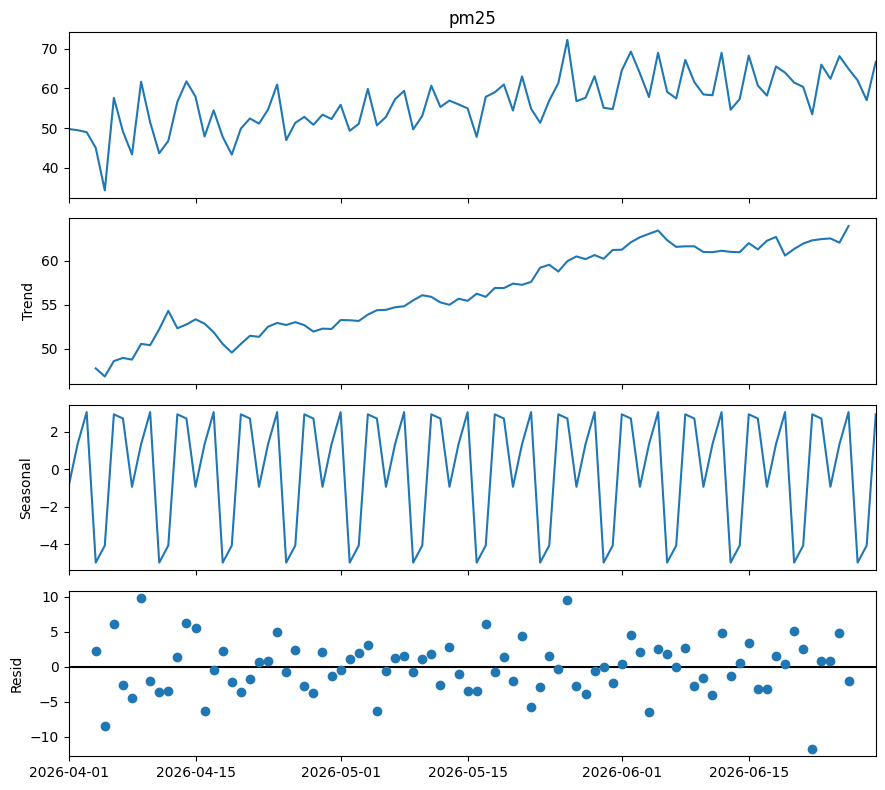

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Construir serie diaria
serie_diaria = df.set_index('fecha')['pm25'].resample('D').median()

# Revisar valores faltantes
print('Días sin datos:', serie_diaria.isna().sum())

# Descomposición semanal
desc = seasonal_decompose(
    serie_diaria.dropna(),
    model='additive',
    period=7
)

# Graficar
fig = desc.plot()
fig.set_size_inches(9, 8)

plt.tight_layout()
plt.show()

In [ ]:
# from statsmodels.tsa.seasonal import seasonal_decompose
# desc = seasonal_decompose(serie, model='additive', period=12)
# fig = desc.plot(); fig.set_size_inches(9, 8); plt.tight_layout(); plt.show()

# Tu código aquí


_Tu lectura de la tendencia, la estacionalidad y el residuo:_



Se distinguen cuatro componentes:

1. Serie original\
El primer gráfico muestra las concentraciones diarias de PM2.5.
- Las concentraciones fluctúan aproximadamente entre 40 y 70 µg/m³.
- Se observa un aumento general desde abril hacia junio.
- Existen días con concentraciones más elevadas, especialmente durante la segunda mitad del período.
Interpretación: la concentración típica diaria de PM2.5 tiende a aumentar durante los tres meses analizados.
2. Tendencia \
El segundo gráfico muestra una tendencia claramente creciente.
- A comienzos de abril, la tendencia se sitúa alrededor de 48 µg/m³.
- Durante mayo aumenta progresivamente.
- En junio alcanza valores cercanos a 65 µg/m³.
Esto indica que las concentraciones de PM2.5 aumentan de manera sostenida en el período estudiado, aunque existen pequeñas fluctuaciones.

Una posible explicación es el cambio estacional hacia los meses más fríos, pero el gráfico no permite demostrar esa causa.

3. Estacionalidad \
El tercer gráfico muestra un patrón semanal estimado que se repite cada siete días.
- Las variaciones estacionales oscilan aproximadamente entre -4 y +3 µg/m³.
- Se observa una repetición regular de aumentos y disminuciones.
- La magnitud de estas variaciones es menor que el incremento observado en la tendencia.
Importante: el método fue configurado con period=7, por lo que el algoritmo estima y repite un componente semanal. Esto no demuestra por sí solo que exista una estacionalidad semanal real.

Para confirmarla, sería conveniente comparar las concentraciones por día de la semana.

4. Residuo \
El cuarto gráfico muestra las variaciones que no son explicadas por la tendencia ni por el componente semanal estimado.

Se observa que:
- La mayoría de los residuos se encuentra aproximadamente entre -5 y +5 µg/m³.
- Existen algunos residuos positivos cercanos a +10 µg/m³.
- También aparece un residuo negativo cercano a -12 µg/m³ hacia finales de junio.
Estos valores podrían corresponder a días con concentraciones inusuales respecto del comportamiento esperado por la descomposición.

Sin embargo, un residuo elevado no significa necesariamente un error en los datos. Podría reflejar un episodio real de contaminación o condiciones ambientales particulares.

### ✏️ Actividad 3.3 — La comparación honesta

Si tu serie tiene estacionalidad, calcula la variación entre dos períodos consecutivos y la variación interanual del mismo período. Muestra la diferencia entre ambas lecturas (Ejercicio 6).

++++\
Esta actividad busca demostrar que comparar dos períodos consecutivos no es lo mismo que comparar el mismo período de años diferentes, especialmente cuando existe estacionalidad.

En tu conjunto de datos tenemos mediciones de PM2.5 entre abril y junio de 2026.

Comparación--Ejemplo--¿Qué permite observar?\
Variación entre períodos consecutivos--Mayo 2026 frente a abril 202--Cambio de un mes al siguiente\
Variación interanual--Mayo 2026 frente a mayo 2026--Cambio respecto del mismo mes del año anterior.

La comparación interanual es útil porque permite reducir el efecto de patrones estacionales que se repiten cada año.

In [ ]:
# Tu código aquí
#Código para calcular la variación mensual
import pandas as pd

# Asegurar formato de fecha
df['fecha'] = pd.to_datetime(df['fecha'])

# Construir serie mensual
serie = df.set_index('fecha')['pm25'].resample('MS').median()

# Variación mensual porcentual
variacion_mensual = serie.pct_change() * 100

# Variación interanual porcentual
variacion_interanual = serie.pct_change(periods=12, fill_method=None) * 100

# Tabla de resultados
tabla = pd.DataFrame({
    'Mediana PM2.5': serie,
    'Variación mensual (%)': variacion_mensual,
    'Variación interanual (%)': variacion_interanual
})

display(tabla.round(2))

,Mediana PM2.5,Variación mensual (%),Variación interanual (%)
fecha,,,
2026-04-01,51.30,NaN,NaN
2026-05-01,57.25,11.60,NaN
2026-06-01,61.45,7.34,NaN


Interpretación de la Actividad 3.3 — La comparación honesta\
Los resultados muestran que la mediana de PM2.5 aumentó durante los tres meses analizados, aunque el incremento porcentual fue menor entre mayo y junio.
Esto significa que las concentraciones típicas continuaron aumentando, pero a un ritmo porcentual menor.

NaN significa que no existe un valor disponible para realizar el cálculo.
Como este conjunto contiene solamente abril, mayo y junio de 2026, no es posible comparar esos meses con los correspondientes de 2025.\
Por lo tanto, no podemos determinar si el aumento observado corresponde a un patrón estacional habitual o a un incremento excepcional.

La comparación mensual muestra que la contaminación aumentó durante el período estudiado.

Sin embargo, una comparación interanual permitiría evaluar si las concentraciones son mayores o menores que las registradas en los mismos meses del año anterior, reduciendo así la influencia de la estacionalidad anual.

---
## Parte 4 · Hipótesis de trabajo

Esto es lo que la semana 4 va a poner a prueba. Una hipótesis de trabajo no es una corazonada: es una afirmación **falsable** que surge de la evidencia que acabas de producir.

### ✏️ Actividad 4.1 — Formula dos hipótesis

Cada una debe indicar:

- **La afirmación**, en una frase.
- **La evidencia exploratoria** que la sugiere (qué gráfico, qué número, en qué celda).
- **Qué la refutaría**: qué tendrías que observar para descartarla.
- **Qué confundidor podría explicarla** sin que la relación sea real.

Si no puedes escribir qué la refutaría, no es una hipótesis: es una opinión.

A partir de los análisis exploratorios realizados sobre este conjunto de datos de calidad del aire, podemos formular dos hipótesis que sean medibles, comprobables y falsables.

Se propone una hipótesis relacionada con las diferencias entre estaciones y otra con la evolución temporal de PM2.5.:\
**Hipótesis 1 — Diferencias de contaminación entre estaciones**\
Afirmación: La concentración típica de PM2.5 en la estación Temuco Padre Las Casas es mayor que en la estación Talcahuano durante el período abril-junio de 2026.

Evidencia exploratoria: En la Actividad 2.1, el análisis mediante groupby() mostró que Temuco Padre Las Casas tiene una mediana de 74,75 µg/m³, mientras que Talcahuano presenta una mediana de 40,40 µg/m³. Ambas estaciones cuentan con una cantidad similar de mediciones válidas (82 y 87, respectivamente).

Qué la refutaría: Que un análisis estadístico posterior no encuentre evidencia suficiente de que la mediana de PM2.5 en Temuco Padre Las Casas sea mayor que en Talcahuano, o que la diferencia desaparezca al controlar factores relevantes.

Confundidor posible: Las condiciones meteorológicas, como la temperatura, la humedad o la ventilación atmosférica, podrían influir en las concentraciones de PM2.5 y explicar parte de las diferencias entre estaciones.

**Hipótesis 2 — Aumento temporal de PM2.5**\
Afirmación: La concentración típica de PM2.5 aumenta entre abril y junio de 2026 en las estaciones de monitoreo analizadas.

Evidencia exploratoria: En la Actividad 3.3, la mediana mensual de PM2.5 aumentó desde 51,30 µg/m³ en abril hasta 57,25 µg/m³ en mayo y 61,45 µg/m³ en junio. Las variaciones mensuales fueron positivas: 11,60% y 7,34%, respectivamente. La tendencia creciente también se observó en la descomposición temporal de la Actividad 3.2.

Qué la refutaría: Que al analizar las estaciones individualmente no se observe un incremento consistente de PM2.5 entre abril y junio, o que el aumento general desaparezca al controlar las diferencias de composición y disponibilidad de mediciones entre estaciones.

Confundidor posible: El descenso estacional de las temperaturas y los cambios asociados en el uso de calefacción podrían explicar parte del incremento observado, sin que exista una tendencia creciente independiente de las condiciones estacionales.

---
## Parte 5 · Cierre y versionado

In [ ]:
# Guarda el conjunto con las variables derivadas que hayas creado esta semana
df.to_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', index=False)
print('Guardado:', df.shape)

Guardado: (720, 12)


In [ ]:
# En una terminal:
# git add S3_Notebook_Laboratorio_CDD.ipynb mi_conjunto_explorado.csv
# git commit -m 'Semana 3: analisis exploratorio y series temporales'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de entregar

- [ ] Al menos tres distribuciones graficadas y **leídas**, no solo mostradas
- [ ] Media contra mediana decidida y justificada
- [ ] Comparación por grupos con el `count` incluido
- [ ] Matriz de correlación calculada e interpretada
- [ ] El par más correlacionado sometido al recorrido de confundidores
- [ ] Serie temporal descompuesta, con lectura del residuo (o justificación de por qué no aplica)
- [ ] Dos hipótesis de trabajo, cada una con qué la refutaría
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

Recuerda: **esta semana no hay sesión sincrónica**. Las dudas, al Foro de Consultas.

_Ciencia de Datos · Advance UCSC · Semana 3_